# Lab 6 — Máy vectơ hỗ trợ (SVM)

Nguyễn Đình Huy — MSSV: 2474802010140

Mỗi mục/bài có một cell code. Chạy từ thư mục Lab hoặc `code/`; giữ CSV trong `data/`. Trên Colab có thể tải cả ba CSV vào thư mục hiện tại. Hình lưu vào `figures/`; chạy `scripts/run_all.py` để cập nhật notebook và xuất nhật ký vào `outputs/`.

## Mục 2 — Đường có lề rộng nhất (g1_le_rong_nhat.py)

w1 = -0.831, w2 = -0.355, b = 4.820
Do rong cua le = 2 / 0.9039 = 2.2126

So vecto ho tro: 3
  diem 18: x1 = 5.20, x2 = 4.22, lop 0, f(x) = -1.000
  diem 10: x1 = 2.88, x2 = 4.02, lop 1, f(x) = +1.000
  diem 13: x1 = 3.59, x2 = 2.36, lop 1, f(x) = +1.000

|f(x)| nho nhat cua cac diem khac: 1.059

Hoc lai chi voi vecto ho tro:
  w1 = -0.831, w2 = -0.355, b = 4.821

Diem (3.0, 3.0): f(x) = +1.262, doan lop 1
Diem (5.0, 4.5): f(x) = -0.933, doan lop 0


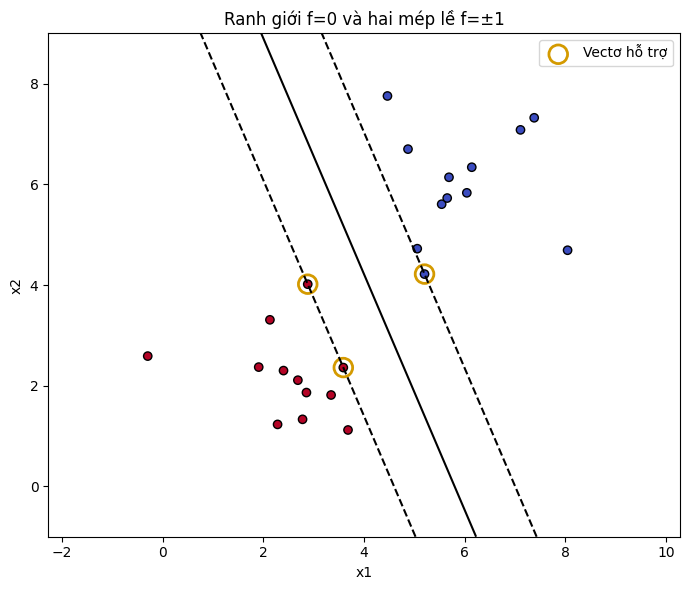

In [1]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# 24 điểm, hai cụm tách hẳn nhau; lớp 1 ở dưới bên trái.
X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y

# C lớn để phạt mạnh các điểm vi phạm lề trên bộ dữ liệu tách được này.
svm = SVC(kernel="linear", C=1000)
svm.fit(X, y)
w = svm.coef_[0]
b = svm.intercept_[0]
print(f"w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f}")
do_dai_w = np.sqrt(w[0] ** 2 + w[1] ** 2)
print(f"Do rong cua le = 2 / {do_dai_w:.4f} = {2 / do_dai_w:.4f}")
print()
print("So vecto ho tro:", len(svm.support_))
for i in svm.support_:
    f = svm.decision_function(X[i:i + 1])[0]
    print(f"  diem {i:2d}: x1 = {X[i, 0]:.2f}, x2 = {X[i, 1]:.2f},"
          f" lop {y[i]}, f(x) = {f:+.3f}")
print()
f_tat_ca = svm.decision_function(X)
ngoai = np.setdiff1d(np.arange(len(X)), svm.support_)
nho_nhat = np.abs(f_tat_ca[ngoai]).min()
print(f"|f(x)| nho nhat cua cac diem khac: {nho_nhat:.3f}")
print()
chi_sv = SVC(kernel="linear", C=1000)
chi_sv.fit(X[svm.support_], y[svm.support_])
w2 = chi_sv.coef_[0]
print("Hoc lai chi voi vecto ho tro:")
b2 = chi_sv.intercept_[0]
print(f"  w1 = {w2[0]:.3f}, w2 = {w2[1]:.3f}, b = {b2:.3f}")
print()
moi = np.array([[3.0, 3.0], [5.0, 4.5]])
for diem, f, lop in zip(moi, svm.decision_function(moi), svm.predict(moi)):
    print(f"Diem ({diem[0]}, {diem[1]}): f(x) = {f:+.3f}, doan lop {lop}")

# Vẽ ranh giới f=0 và hai mép lề f=±1, không đổi mô hình của thầy.
xx, yy = np.meshgrid(np.linspace(-1, 9, 240), np.linspace(-1, 9, 240))
f_luoi = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
plt.contour(xx, yy, f_luoi, levels=[-1, 0, 1], colors="black", linestyles=["--", "-", "--"])
plt.scatter(X[svm.support_, 0], X[svm.support_, 1], s=180,
            facecolors="none", edgecolors="#d49a00", linewidths=2, label="Vectơ hỗ trợ")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Ranh giới f=0 và hai mép lề f=±1")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.savefig(thu_muc_hinh / "le_rong_nhat.png", dpi=150)
plt.show()
plt.close()


## Mục 3 — Lề mềm, tham số C và chuẩn hóa (g2_tham_so_c.py)

Tap hoc co 90 ban
   C   so vecto HT  do rong le  tap hoc  tap kiem tra
   0.01     74        3.84     0.8556   0.8667
    0.1     44        1.70     0.8889   0.9000
      1     31        1.29     0.8778   0.9000
     10     28        1.06     0.9000   0.9000
    100     27        1.05     0.9000   0.9000

Ba cot, kernel RBF mac dinh
  Doan bua ca lop qua : 0.6000
  Khong chuan hoa    : 0.6000
  Co chuan hoa       : 0.9000


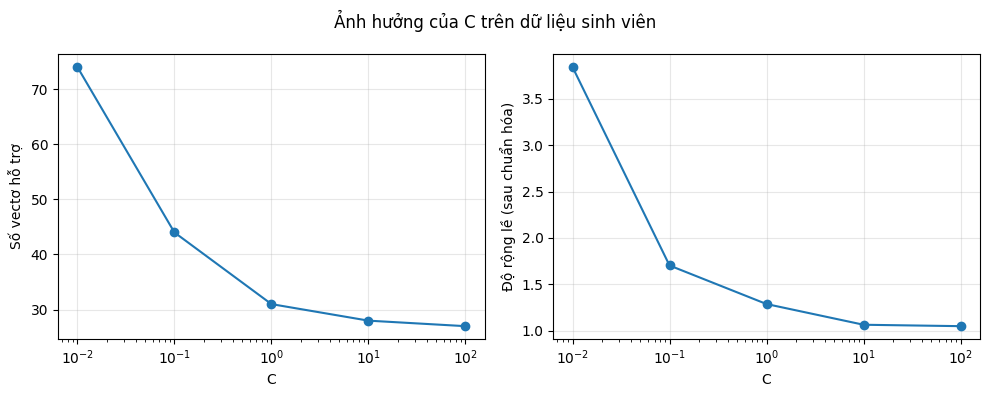

In [2]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv(tep_du_lieu("sinh_vien.csv"))
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print("Tap hoc co", len(X_tr), "ban")
print("   C   so vecto HT  do rong le  tap hoc  tap kiem tra")
ket_qua_c = []
for C in [0.01, 0.1, 1, 10, 100]:
    mh = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C))
    mh.fit(X_tr, y_tr)
    svm = mh[-1]
    le = 2 / np.linalg.norm(svm.coef_[0])
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f" {C:6} {len(svm.support_):6d}      {le:6.2f}"
          f"     {a_hoc:.4f}   {a_kt:.4f}")
    ket_qua_c.append((C, len(svm.support_), le))
print()
# Cột chi tiêu có đơn vị nghìn đồng, khác thang đo hai cột học tập.
df3 = pd.read_csv(tep_du_lieu("sinh_vien_mo_rong.csv"))
X3 = df3[["gio_on", "diem_giua_ky", "chi_tieu"]]
y3 = df3["qua_mon"]
X3_tr, X3_te, y3_tr, y3_te = train_test_split(
    X3, y3, test_size=0.25, random_state=17, stratify=y3
)
tho = SVC().fit(X3_tr, y3_tr)
chuan = make_pipeline(StandardScaler(), SVC()).fit(X3_tr, y3_tr)
print("Ba cot, kernel RBF mac dinh")
print(f"  Doan bua ca lop qua : {y3_te.mean():.4f}")
print(f"  Khong chuan hoa    : {accuracy_score(y3_te, tho.predict(X3_te)):.4f}")
print(f"  Co chuan hoa       : {accuracy_score(y3_te, chuan.predict(X3_te)):.4f}")

bang_c = np.array(ket_qua_c)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, cot, nhan in [(axes[0], 1, "Số vectơ hỗ trợ"), (axes[1], 2, "Độ rộng lề (sau chuẩn hóa)")]:
    ax.semilogx(bang_c[:, 0], bang_c[:, cot], "o-")
    ax.set_xlabel("C")
    ax.set_ylabel(nhan)
    ax.grid(alpha=0.3)
fig.suptitle("Ảnh hưởng của C trên dữ liệu sinh viên")
fig.tight_layout()
fig.savefig(thu_muc_hinh / "tham_so_c.png", dpi=150)
plt.show()
plt.close(fig)


## Mục 4 — Nâng chiều và kernel (g3_kernel.py)

Mot nguong tren truc x, tot nhat dung 0.7143
Them cot x^2, SVM tuyen tinh dung 1.0000



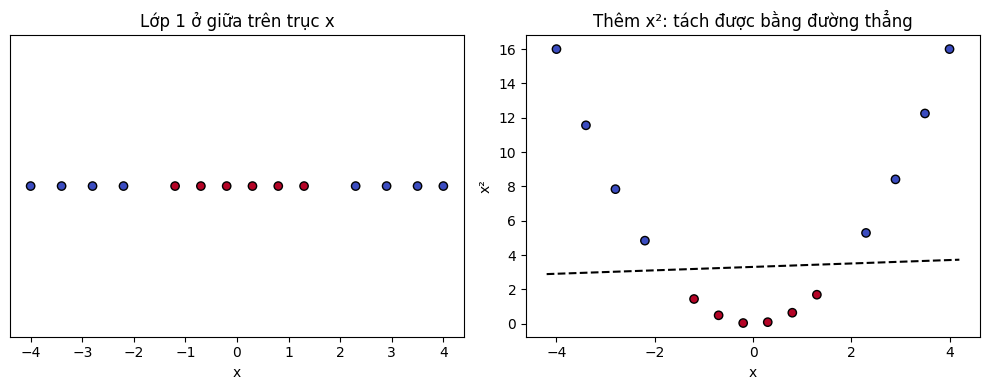

Hai vang trang, accuracy tren tap kiem tra
  SVM kernel tuyen tinh      0.8667
  SVM kernel da thuc bac 3   0.8667
  SVM kernel RBF             0.9200
  Hoi quy logistic           0.8533
  KNN, k = 13                0.9200

So vecto ho tro cua kernel RBF: 89 tren 225 diem hoc


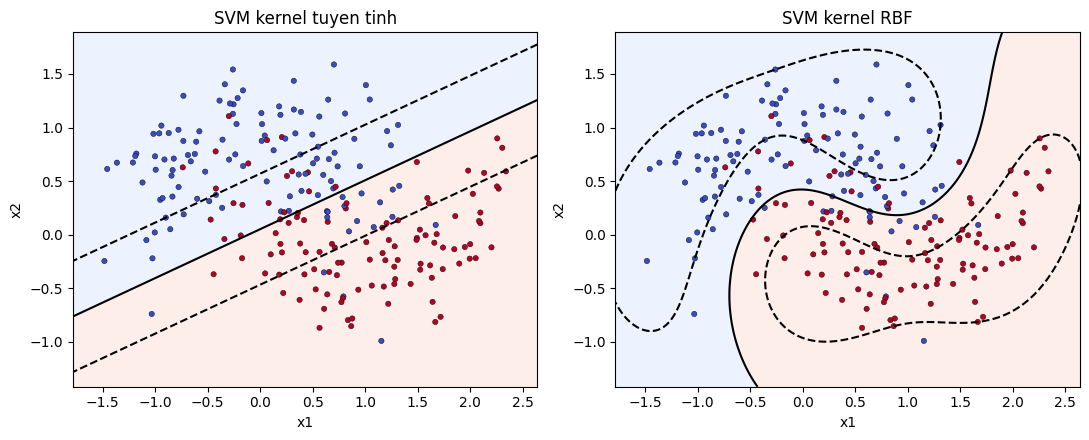

In [3]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

x = np.array([-4.0, -3.4, -2.8, -2.2, -1.2, -0.7, -0.2,
              0.3, 0.8, 1.3, 2.3, 2.9, 3.5, 4.0])
y = (np.abs(x) < 1.8).astype(int)
tot = max(((x <= t).astype(int) == y).mean() for t in x)
print(f"Mot nguong tren truc x, tot nhat dung {tot:.4f}")
X_moi = np.c_[x, x ** 2]
svm = SVC(kernel="linear", C=1000).fit(X_moi, y)
print(f"Them cot x^2, SVM tuyen tinh dung {svm.score(X_moi, y):.4f}")
print()

# Lưu minh họa nâng chiều trước khi chuyển sang dữ liệu hai vầng trăng.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(x, np.zeros_like(x), c=y, cmap="coolwarm", edgecolors="k")
axes[0].set(xlabel="x", title="Lớp 1 ở giữa trên trục x", yticks=[])
axes[1].scatter(x, x ** 2, c=y, cmap="coolwarm", edgecolors="k")
truc_x = np.linspace(-4.2, 4.2, 200)
axes[1].plot(truc_x, -(svm.coef_[0, 0] * truc_x + svm.intercept_[0]) / svm.coef_[0, 1], "k--")
axes[1].set(xlabel="x", ylabel="x²", title="Thêm x²: tách được bằng đường thẳng")
fig.tight_layout()
fig.savefig(thu_muc_hinh / "nang_chieu.png", dpi=150)
plt.show()
plt.close(fig)

df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = {
    "SVM kernel tuyen tinh": SVC(kernel="linear"),
    "SVM kernel da thuc bac 3": SVC(kernel="poly", degree=3),
    "SVM kernel RBF": SVC(kernel="rbf"),
    "Hoi quy logistic": LogisticRegression(),
    "KNN, k = 13": KNeighborsClassifier(n_neighbors=13),
}
print("Hai vang trang, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:26s} {acc:.4f}")
print()
rbf = mo_hinh["SVM kernel RBF"]
print("So vecto ho tro cua kernel RBF:", len(rbf.support_), "tren", len(X_tr), "diem hoc")

xx, yy = np.meshgrid(np.linspace(X.x1.min() - .3, X.x1.max() + .3, 220),
                     np.linspace(X.x2.min() - .3, X.x2.max() + .3, 220))
luoi = pd.DataFrame({"x1": xx.ravel(), "x2": yy.ravel()})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, ten in zip(axes, ["SVM kernel tuyen tinh", "SVM kernel RBF"]):
    f = mo_hinh[ten].decision_function(luoi).reshape(xx.shape)
    ax.contourf(xx, yy, f > 0, alpha=.16, cmap="coolwarm")
    ax.contour(xx, yy, f, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.scatter(X_tr.x1, X_tr.x2, c=y_tr, cmap="coolwarm", s=15, edgecolors="k", linewidths=.3)
    ax.set(title=ten, xlabel="x1", ylabel="x2")
fig.tight_layout()
fig.savefig(thu_muc_hinh / "so_sanh_kernel.png", dpi=150)
plt.show()
plt.close(fig)


## Mục 5 — Chọn C và gamma (g4_chon_tham_so.py)

gamma  tap hoc  tap kiem tra  so vecto HT
   0.1 0.8356   0.8533        113
     1 0.8711   0.9200        88
    10 0.8978   0.9067        128
   100 0.9422   0.8133        217



Diem kiem dinh cheo, hang la C, cot la gamma
gamma   0.01    0.10    1.00    10.00
C                                    
0.1    0.6578  0.8044  0.8444  0.8578
1.0    0.8044  0.8178  0.8667  0.8667
10.0   0.8178  0.8400  0.8711  0.8311
100.0  0.8178  0.8533  0.8711  0.7467

Cap tot nhat: {'C': 10, 'gamma': 1}
Diem kiem dinh cheo: 0.8711
Accuracy tren tap kiem tra: 0.9200


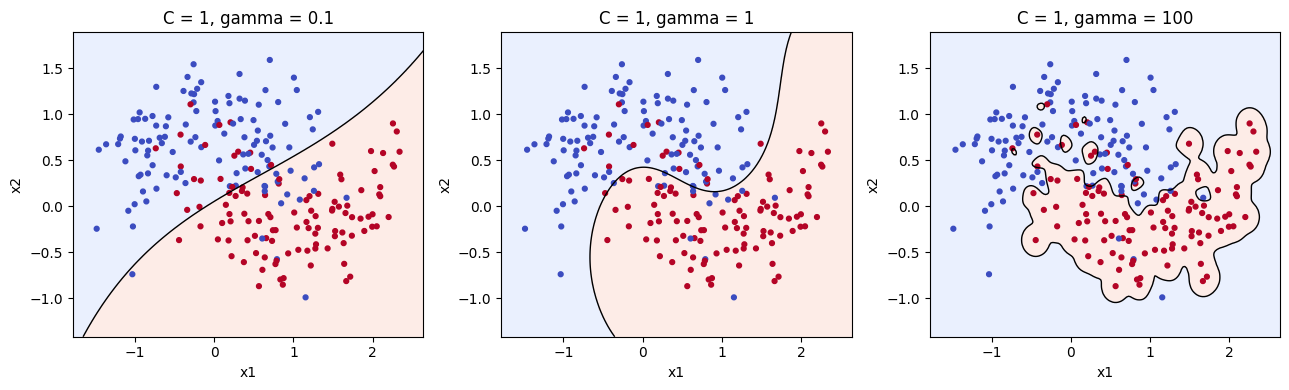

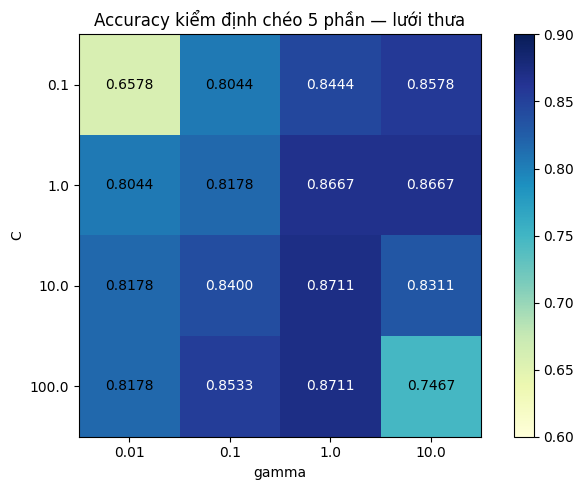

In [4]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC
df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("gamma  tap hoc  tap kiem tra  so vecto HT")
cac_gamma = {}
for g in [0.1, 1, 10, 100]:
    mh = SVC(kernel="rbf", gamma=g).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f" {g:5} {a_hoc:.4f}   {a_kt:.4f}        {len(mh.support_)}")
    cac_gamma[g] = mh
print()
# Chỉ dò tham số trên tập học; GridSearchCV tự fit lại cặp tốt nhất.
luoi = {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}
tim = GridSearchCV(SVC(kernel="rbf"), luoi, cv=5)
tim.fit(X_tr, y_tr)
bang = pd.DataFrame(tim.cv_results_["params"])
bang["diem"] = tim.cv_results_["mean_test_score"]
print("Diem kiem dinh cheo, hang la C, cot la gamma")
print(bang.pivot(index="C", columns="gamma", values="diem").round(4).to_string())
print()
print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo: {tim.best_score_:.4f}")
print(f"Accuracy tren tap kiem tra: {tim.score(X_te, y_te):.4f}")

xx, yy = np.meshgrid(np.linspace(X.x1.min() - .3, X.x1.max() + .3, 200),
                     np.linspace(X.x2.min() - .3, X.x2.max() + .3, 200))
diem_luoi = pd.DataFrame({"x1": xx.ravel(), "x2": yy.ravel()})
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, g in zip(axes, [0.1, 1, 100]):
    f = cac_gamma[g].decision_function(diem_luoi).reshape(xx.shape)
    ax.contourf(xx, yy, f > 0, alpha=.18, cmap="coolwarm")
    ax.contour(xx, yy, f, levels=[0], colors="k", linewidths=1)
    ax.scatter(X_tr.x1, X_tr.x2, c=y_tr, cmap="coolwarm", s=12)
    ax.set(title=f"C = 1, gamma = {g}", xlabel="x1", ylabel="x2")
fig.tight_layout()
fig.savefig(thu_muc_hinh / "anh_huong_gamma.png", dpi=150)
plt.show()
plt.close(fig)

ma_tran = bang.pivot(index="C", columns="gamma", values="diem")
fig, ax = plt.subplots(figsize=(7, 5))
anh = ax.imshow(ma_tran, cmap="YlGnBu", vmin=.6, vmax=.9)
ax.set_xticks(range(len(ma_tran.columns)), ma_tran.columns)
ax.set_yticks(range(len(ma_tran.index)), ma_tran.index)
for i in range(len(ma_tran.index)):
    for j in range(len(ma_tran.columns)):
        ax.text(j, i, f"{ma_tran.iloc[i, j]:.4f}", ha="center", va="center",
                color="white" if ma_tran.iloc[i, j] > .82 else "black")
ax.set(xlabel="gamma", ylabel="C", title="Accuracy kiểm định chéo 5 phần — lưới thưa")
fig.colorbar(anh, ax=ax)
fig.tight_layout()
fig.savefig(thu_muc_hinh / "luoi_tham_so.png", dpi=150)
plt.show()
plt.close(fig)


## Mục 6 — Nhận dạng chữ số viết tay (g5_chu_so.py)

Kich thuoc X: (1797, 64)
Do sang nho nhat va lon nhat: 0.0 16.0
So anh moi chu so: [178 182 177 183 181 182 181 179 174 180]

SVM kernel RBF: accuracy 0.9911
So vecto ho tro: 626 tren 1347 anh
So anh doan sai: 4 tren 450
  anh   6: that la 9, doan la 3
  anh  18: that la 8, doan la 1
  anh 161: that la 4, doan la 8
  anh 428: that la 7, doan la 9

Cac mo hinh khac, accuracy tren tap kiem tra
  SVM co chuan hoa       0.9778


  KNN, k = 5             0.9867
  Logistic co chuan hoa  0.9711


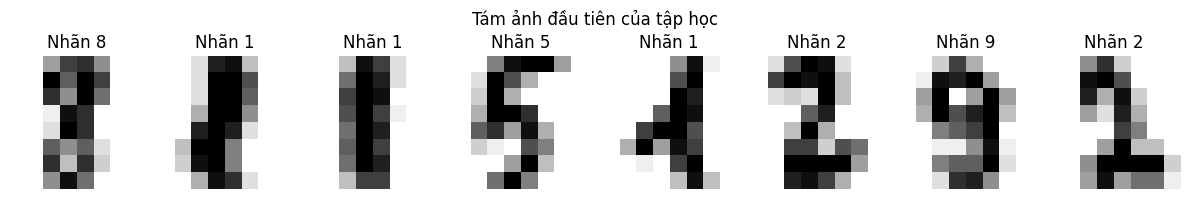

In [5]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
print("Kich thuoc X:", X.shape)
print("Do sang nho nhat va lon nhat:", X.min(), X.max())
print("So anh moi chu so:", np.bincount(y))
print()
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)
print(f"SVM kernel RBF: accuracy {accuracy_score(y_te, du_doan):.4f}")
print("So vecto ho tro:", len(svm.support_), "tren", len(X_tr), "anh")
sai = np.flatnonzero(du_doan != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f"  anh {i:3d}: that la {y_te[i]}, doan la {du_doan[i]}")
print()
mo_hinh = {
    "SVM co chuan hoa": make_pipeline(StandardScaler(), SVC()),
    "KNN, k = 5": KNeighborsClassifier(),
    "Logistic co chuan hoa": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
}
print("Cac mo hinh khac, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:22s} {acc:.4f}")

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_tr[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Nhãn {y_tr[i]}")
    ax.axis("off")
fig.suptitle("Tám ảnh đầu tiên của tập học")
fig.tight_layout()
fig.savefig(thu_muc_hinh / "chu_so_tap_hoc.png", dpi=150)
plt.show()
plt.close(fig)
